# Tugas - Medical Cost Prediction

| Nama | NRP |
|------|-----|
| Faiz Farrosian Karim | 5054251027 |

## Deskripsi Tugas

Pada tugas ini, kita akan menggunakan Medical Cost Personal Dataset dari Kaggle.

Dataset:
- https://www.kaggle.com/mirichoi0218/insurance

Target yang diprediksi adalah `charges`.

Model yang digunakan:
1. Linear Regression
2. Polynomial Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Support Vector Regression


# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
RANDOM_STATE = 42

In [2]:
# Load dataset.
# Sesuaikan nama file dengan file dataset yang digunakan.
df = pd.read_csv("insurance.csv")

In [3]:
# Tampilkan beberapa baris pertama dataset.
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
# Tampilkan informasi dataset.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [5]:
# Periksa missing value.
print("Jumlah missing value per kolom:")
print(df.isnull().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

Jumlah missing value per kolom:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Jumlah baris duplikat: 1


In [6]:
# Tampilkan statistik deskriptif fitur numerik.
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
# Tampilkan jumlah nilai pada setiap fitur kategorikal.
for col in ["sex", "smoker", "region"]:
    print(df[col].value_counts())
    print()

sex
male      676
female    662
Name: count, dtype: int64

smoker
no     1064
yes     274
Name: count, dtype: int64

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64



## Lakukan Exploratory Data Analysis (EDA) sederhana yang diperlukan.


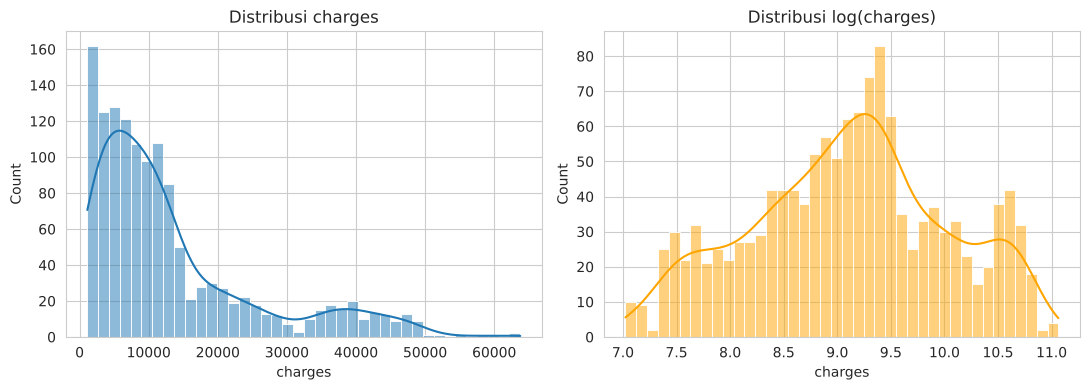

In [8]:
# Distribusi target (charges) dan log-nya
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["charges"], bins=40, kde=True, ax=ax[0])
ax[0].set_title("Distribusi charges")
sns.histplot(np.log(df["charges"]), bins=40, kde=True, ax=ax[1], color="orange")
ax[1].set_title("Distribusi log(charges)")
plt.tight_layout()
plt.show()

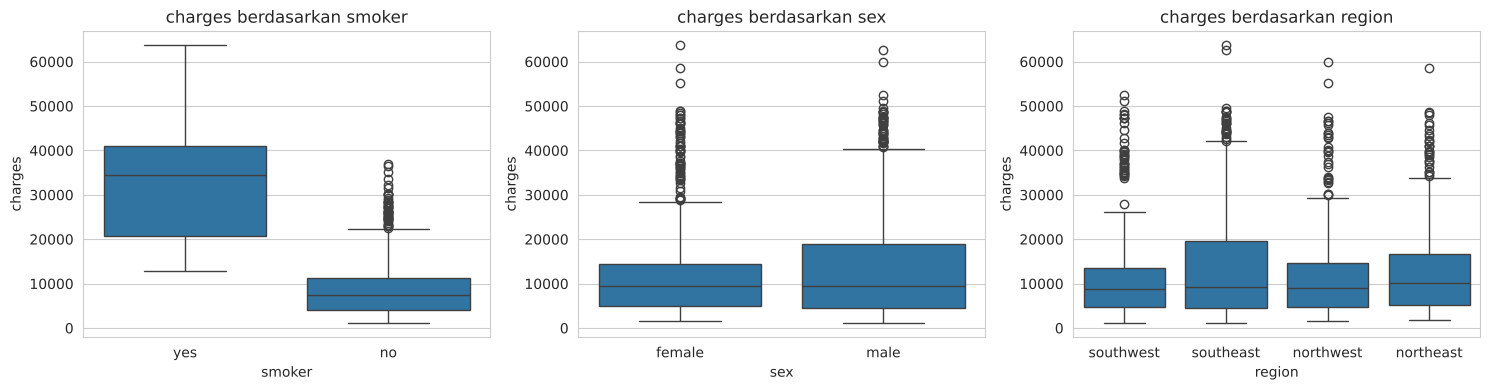

In [9]:
# Pengaruh fitur kategorikal terhadap charges
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["smoker", "sex", "region"]):
    sns.boxplot(data=df, x=col, y="charges", ax=a)
    a.set_title(f"charges berdasarkan {col}")
plt.tight_layout()
plt.show()

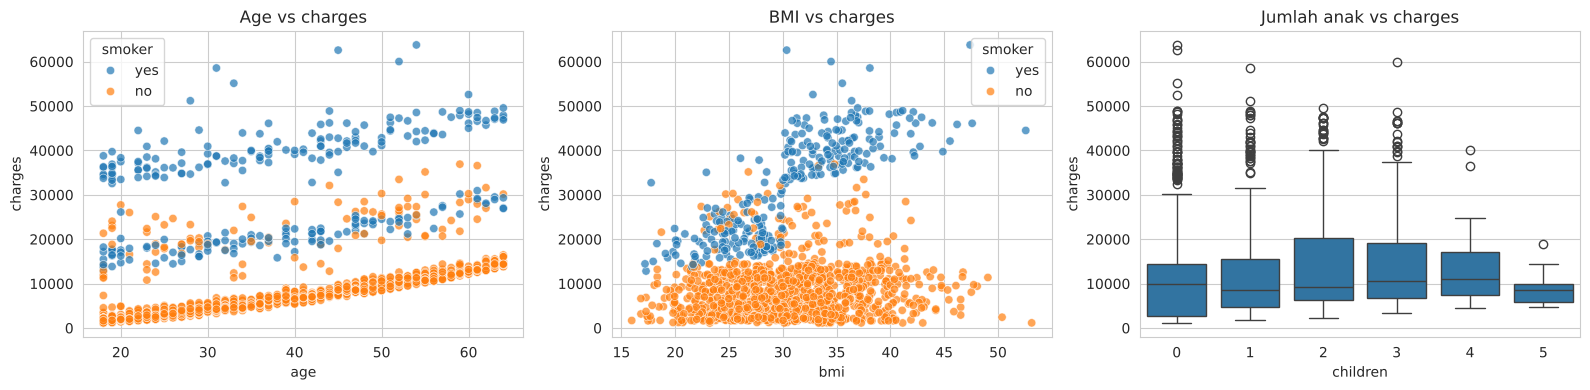

In [10]:
# Pengaruh fitur numerik terhadap charges, diwarnai status perokok
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=0.7, ax=ax[0])
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=0.7, ax=ax[1])
sns.boxplot(data=df, x="children", y="charges", ax=ax[2])
ax[0].set_title("Age vs charges")
ax[1].set_title("BMI vs charges")
ax[2].set_title("Jumlah anak vs charges")
plt.tight_layout()
plt.show()

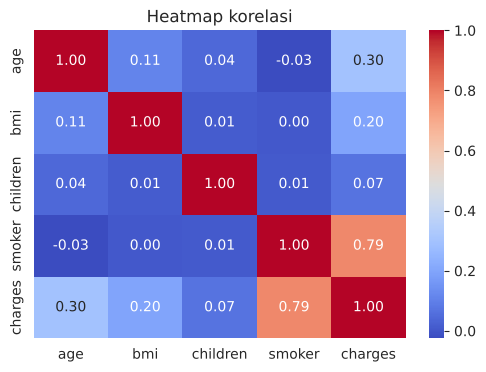

In [11]:
# Korelasi antar fitur numerik (smoker diubah ke 0/1 hanya untuk EDA)
df_eda = df.copy()
df_eda["smoker"] = (df_eda["smoker"] == "yes").astype(int)
plt.figure(figsize=(6, 4))
sns.heatmap(df_eda[["age", "bmi", "children", "smoker", "charges"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Heatmap korelasi")
plt.show()

**Hasil EDA:**

- Dataset berisi 1338 baris dan 7 kolom, tidak ada missing value. Ada 1 baris duplikat, tetapi dibiarkan karena jumlahnya sangat kecil dan bisa saja merupakan data orang yang berbeda.
- Distribusi `charges` miring ke kanan (skewness sekitar 1,5): kebanyakan biaya rendah, tetapi ada sebagian kecil biaya yang sangat tinggi.
- Fitur yang paling berpengaruh adalah `smoker`. Median biaya perokok sekitar 34 ribu, sedangkan non-perokok sekitar 7 ribu.
- Pada scatter plot `age` vs `charges`, terlihat tiga kelompok titik. Biaya naik seiring usia, dan perokok berada di kelompok paling atas.
- Pada `bmi` vs `charges`, perokok dengan BMI di atas 30 punya biaya paling tinggi. Artinya ada **interaksi** antara `smoker` dan `bmi`, bukan hubungan linear sederhana.
- `sex`, `region`, dan `children` terlihat hampir tidak membedakan biaya.

# 2. Preprocessing

Pisahkan fitur numerik dan kategorikal. Gunakan OneHotEncoder untuk fitur kategorikal.

Model Linear Regression, Polynomial Regression, Ridge, Lasso, dan SVR menggunakan data yang telah di-scaling. Decision Tree Regressor tidak memerlukan scaling.


In [12]:
# Pisahkan fitur (X) dan target (y).
X = df.drop("charges", axis=1)
y = df["charges"]
print(X.shape, y.shape)

(1338, 6) (1338,)


In [13]:
# Identifikasi kolom numerik dan kategorikal.
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
print("Numerik     :", numeric_features)
print("Kategorikal :", categorical_features)

Numerik     : ['age', 'bmi', 'children']
Kategorikal : ['sex', 'smoker', 'region']


In [14]:
# Bagi data menjadi train set dan test set.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1070, 6) | Test: (268, 6)


In [15]:
# Buat preprocessing untuk fitur numerik dan kategorikal.
# (a) Preprocessing dengan scaling -> untuk Linear, Polynomial, Ridge, Lasso, SVR
# drop="first" supaya tidak ada dummy variable trap pada model linear
preprocess_scaled = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(drop="first"), categorical_features),
])

# (b) Preprocessing tanpa scaling -> untuk Decision Tree
preprocess_tree = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("cat", OneHotEncoder(drop="first"), categorical_features),
])

# fit hanya pada data train agar tidak terjadi data leakage
X_train_scaled = preprocess_scaled.fit_transform(X_train)
X_test_scaled = preprocess_scaled.transform(X_test)

X_train_tree = preprocess_tree.fit_transform(X_train)
X_test_tree = preprocess_tree.transform(X_test)

feature_names = preprocess_scaled.get_feature_names_out()
print("Fitur setelah preprocessing:", list(feature_names))
print("Shape X_train_scaled:", X_train_scaled.shape)

Fitur setelah preprocessing: ['num__age', 'num__bmi', 'num__children', 'cat__sex_male', 'cat__smoker_yes', 'cat__region_northwest', 'cat__region_southeast', 'cat__region_southwest']
Shape X_train_scaled: (1070, 8)


# 3. Eksperimen Model

## 3.1 Linear Regression

Bangun model Linear Regression menggunakan data hasil preprocessing.


In [16]:
# Inisialisasi dan latih Linear Regression.
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

coef_df = pd.DataFrame({"fitur": feature_names, "koefisien": lin_reg.coef_})
print("Intercept:", round(lin_reg.intercept_, 2))
coef_df

Intercept: 8955.24


,fitur,koefisien
0,num__age,3614.975415
1,num__bmi,2036.228123
2,num__children,516.890247
3,cat__sex_male,-18.591692
4,cat__smoker_yes,23651.128856
5,cat__region_northwest,-370.677326
6,cat__region_southeast,-657.864297
7,cat__region_southwest,-809.799354


In [17]:
# Lakukan prediksi pada test set.
pred_lin = lin_reg.predict(X_test_scaled)
print("R2 Linear Regression:", round(r2_score(y_test, pred_lin), 4))

R2 Linear Regression: 0.7836


## 3.2 Polynomial Regression

Gunakan PolynomialFeatures. Tentukan degree berdasarkan eksperimen.


In [18]:
# Buat fitur polynomial dan latih model.
# Cari degree terbaik dengan 5-fold cross validation pada data train
for degree in [1, 2, 3, 4]:
    poly_tmp = PolynomialFeatures(degree=degree, include_bias=False)
    Xp = poly_tmp.fit_transform(X_train_scaled)
    cv = cross_val_score(LinearRegression(), Xp, y_train, cv=5, scoring="r2")
    print(f"degree={degree} | jumlah fitur={Xp.shape[1]:3d} | CV R2={cv.mean():.4f}")

degree=1 | jumlah fitur=  8 | CV R2=0.7331
degree=2 | jumlah fitur= 44 | CV R2=0.8268
degree=3 | jumlah fitur=164 | CV R2=0.8137


degree=4 | jumlah fitur=494 | CV R2=0.7128


In [19]:
# Lakukan prediksi pada test set.
best_degree = 2   # CV R2 tertinggi, lihat hasil di atas
poly = PolynomialFeatures(degree=best_degree, include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

poly_reg = LinearRegression()
poly_reg.fit(X_train_poly, y_train)
pred_poly = poly_reg.predict(X_test_poly)
print("Degree dipakai:", best_degree)
print("R2 Polynomial Regression:", round(r2_score(y_test, pred_poly), 4))

Degree dipakai: 2
R2 Polynomial Regression: 0.8666


## 3.3 Ridge Regression

Gunakan Ridge Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [20]:
# Inisialisasi dan latih Ridge Regression.
# Cari alpha Ridge dengan cross validation
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
for a in alphas:
    cv = cross_val_score(Ridge(alpha=a), X_train_scaled, y_train, cv=5, scoring="r2")
    print(f"alpha={a:<7} | CV R2={cv.mean():.4f}")

alpha=0.001   | CV R2=0.7331
alpha=0.01    | CV R2=0.7331
alpha=0.1     | CV R2=0.7331
alpha=1       | CV R2=0.7332
alpha=10      | CV R2=0.7308
alpha=100     | CV R2=0.6228


In [21]:
# Lakukan prediksi pada test set.
ridge = Ridge(alpha=1)
ridge.fit(X_train_scaled, y_train)
pred_ridge = ridge.predict(X_test_scaled)
print("R2 Ridge:", round(r2_score(y_test, pred_ridge), 4))

R2 Ridge: 0.7833


## 3.4 Lasso Regression

Gunakan Lasso Regression. Tentukan nilai alpha berdasarkan eksperimen.


In [22]:
# Inisialisasi dan latih Lasso Regression.
# Cari alpha Lasso dengan cross validation
for a in [0.01, 0.1, 1, 10, 100, 500]:
    cv = cross_val_score(Lasso(alpha=a, max_iter=10000), X_train_scaled, y_train, cv=5, scoring="r2")
    print(f"alpha={a:<7} | CV R2={cv.mean():.4f}")

alpha=0.01    | CV R2=0.7331
alpha=0.1     | CV R2=0.7331
alpha=1       | CV R2=0.7331
alpha=10      | CV R2=0.7333
alpha=100     | CV R2=0.7342
alpha=500     | CV R2=0.7199


In [23]:
# Lakukan prediksi pada test set.
lasso = Lasso(alpha=100, max_iter=10000)
lasso.fit(X_train_scaled, y_train)
pred_lasso = lasso.predict(X_test_scaled)
print("R2 Lasso:", round(r2_score(y_test, pred_lasso), 4))

# Koefisien Lasso vs Linear Regression
pd.DataFrame({"fitur": feature_names,
              "Linear": lin_reg.coef_.round(1),
              "Ridge": ridge.coef_.round(1),
              "Lasso": lasso.coef_.round(1)})

R2 Lasso: 0.7793


,fitur,Linear,Ridge,Lasso
0,num__age,3615.0,3609.1,3519.4
1,num__bmi,2036.2,2033.3,1888.6
2,num__children,516.9,517.6,428.2
3,cat__sex_male,-18.6,-10.6,0.0
4,cat__smoker_yes,23651.1,23514.6,23030.9
5,cat__region_northwest,-370.7,-366.2,0.0
6,cat__region_southeast,-657.9,-643.0,-0.0
7,cat__region_southwest,-809.8,-802.9,-0.0


## 3.5 Decision Tree Regressor

Gunakan Decision Tree Regressor. Eksperimen dapat dilakukan pada `max_depth` dan `min_samples_leaf`.


In [24]:
# Inisialisasi dan latih Decision Tree Regressor.
# Eksperimen max_depth dan min_samples_leaf dengan cross validation
hasil_dt = []
for depth in [2, 3, 4, 5, 6, 8, 10]:
    for leaf in [1, 5, 10, 20]:
        dt_tmp = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=RANDOM_STATE)
        cv = cross_val_score(dt_tmp, X_train_tree, y_train, cv=5, scoring="r2")
        hasil_dt.append((depth, leaf, cv.mean()))

dt_result = pd.DataFrame(hasil_dt, columns=["max_depth", "min_samples_leaf", "CV_R2"])
print(dt_result.pivot(index="max_depth", columns="min_samples_leaf", values="CV_R2").round(4))
best = dt_result.sort_values("CV_R2", ascending=False).iloc[0]
print("\nParameter terbaik:", int(best.max_depth), int(best.min_samples_leaf), round(best.CV_R2, 4))

min_samples_leaf      1       5       10      20
max_depth                                       
2                 0.8189  0.8189  0.8189  0.8189
3                 0.8357  0.8357  0.8357  0.8357
4                 0.8374  0.8372  0.8370  0.8370
5                 0.8215  0.8336  0.8351  0.8370
6                 0.8095  0.8227  0.8284  0.8337
8                 0.7740  0.8156  0.8223  0.8308
10                0.7064  0.8023  0.8216  0.8308

Parameter terbaik: 4 1 0.8374


R2 Decision Tree: 0.8641


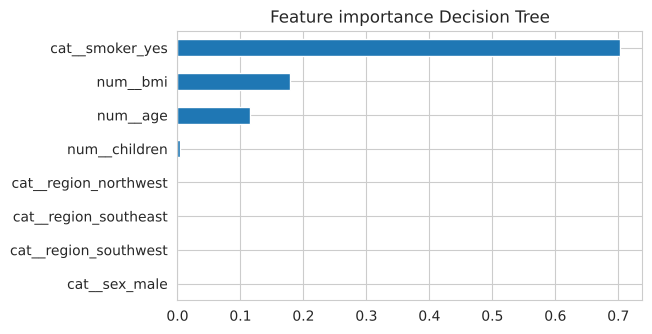

In [25]:
# Lakukan prediksi pada test set.
tree = DecisionTreeRegressor(max_depth=int(best.max_depth),
                             min_samples_leaf=int(best.min_samples_leaf),
                             random_state=RANDOM_STATE)
tree.fit(X_train_tree, y_train)
pred_tree = tree.predict(X_test_tree)
print("R2 Decision Tree:", round(r2_score(y_test, pred_tree), 4))

# Fitur terpenting menurut pohon
imp = pd.Series(tree.feature_importances_, index=feature_names).sort_values()
imp.plot(kind="barh", figsize=(6, 3.5), title="Feature importance Decision Tree")
plt.show()

## 3.6 Support Vector Regression

Gunakan SVR dengan data yang telah di-scaling. Tentukan parameter berdasarkan eksperimen.


In [26]:
# Inisialisasi dan latih SVR.
# Pertama coba SVR dengan parameter default (C=1)
svr_default = SVR()
svr_default.fit(X_train_scaled, y_train)
print("R2 SVR default (C=1):", round(r2_score(y_test, svr_default.predict(X_test_scaled)), 4))

# Eksperimen nilai C dan kernel dengan cross validation
for kernel in ["linear", "rbf"]:
    for C in [100, 1000, 10000, 100000]:
        cv = cross_val_score(SVR(kernel=kernel, C=C), X_train_scaled, y_train, cv=5, scoring="r2")
        print(f"kernel={kernel:<6} C={C:<7} | CV R2={cv.mean():.4f}")

R2 SVR default (C=1): -0.0715


kernel=linear C=100     | CV R2=0.5002


kernel=linear C=1000    | CV R2=0.6331


kernel=linear C=10000   | CV R2=0.6538


kernel=linear C=100000  | CV R2=0.6500
kernel=rbf    C=100     | CV R2=-0.0210


kernel=rbf    C=1000    | CV R2=0.5084


kernel=rbf    C=10000   | CV R2=0.8169


kernel=rbf    C=100000  | CV R2=0.8195


In [27]:
# Lakukan prediksi pada test set.
svr = SVR(kernel="rbf", C=100000)
svr.fit(X_train_scaled, y_train)
pred_svr = svr.predict(X_test_scaled)
print("R2 SVR (rbf, C=100000):", round(r2_score(y_test, pred_svr), 4))

R2 SVR (rbf, C=100000): 0.8668


# 4. Evaluasi Model

In [28]:
# Hitung MAE, MSE, RMSE, dan R² untuk setiap model.
# Sajikan hasil dalam satu tabel perbandingan.
predictions = {
    "Linear Regression": pred_lin,
    "Polynomial Regression (deg 2)": pred_poly,
    "Ridge Regression": pred_ridge,
    "Lasso Regression": pred_lasso,
    "Decision Tree Regressor": pred_tree,
    "SVR (RBF)": pred_svr,
}

rows = []
for name, pred in predictions.items():
    mse = mean_squared_error(y_test, pred)
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, pred),
    })

results = pd.DataFrame(rows).sort_values("R2", ascending=False).reset_index(drop=True)
results.style.format({"MAE": "{:,.2f}", "MSE": "{:,.0f}", "RMSE": "{:,.2f}", "R2": "{:.4f}"}) \
       .background_gradient(subset=["R2"], cmap="Greens")

,Model,MAE,MSE,RMSE,R2
0,SVR (RBF),"1,718.56","20,680,540","4,547.59",0.8668
1,Polynomial Regression (deg 2),"2,729.50","20,712,806","4,551.13",0.8666
2,Decision Tree Regressor,"2,697.77","21,093,484","4,592.76",0.8641
3,Linear Regression,"4,181.19","33,596,916","5,796.28",0.7836
4,Ridge Regression,"4,193.20","33,645,393","5,800.46",0.7833
5,Lasso Regression,"4,248.49","34,266,063","5,853.72",0.7793


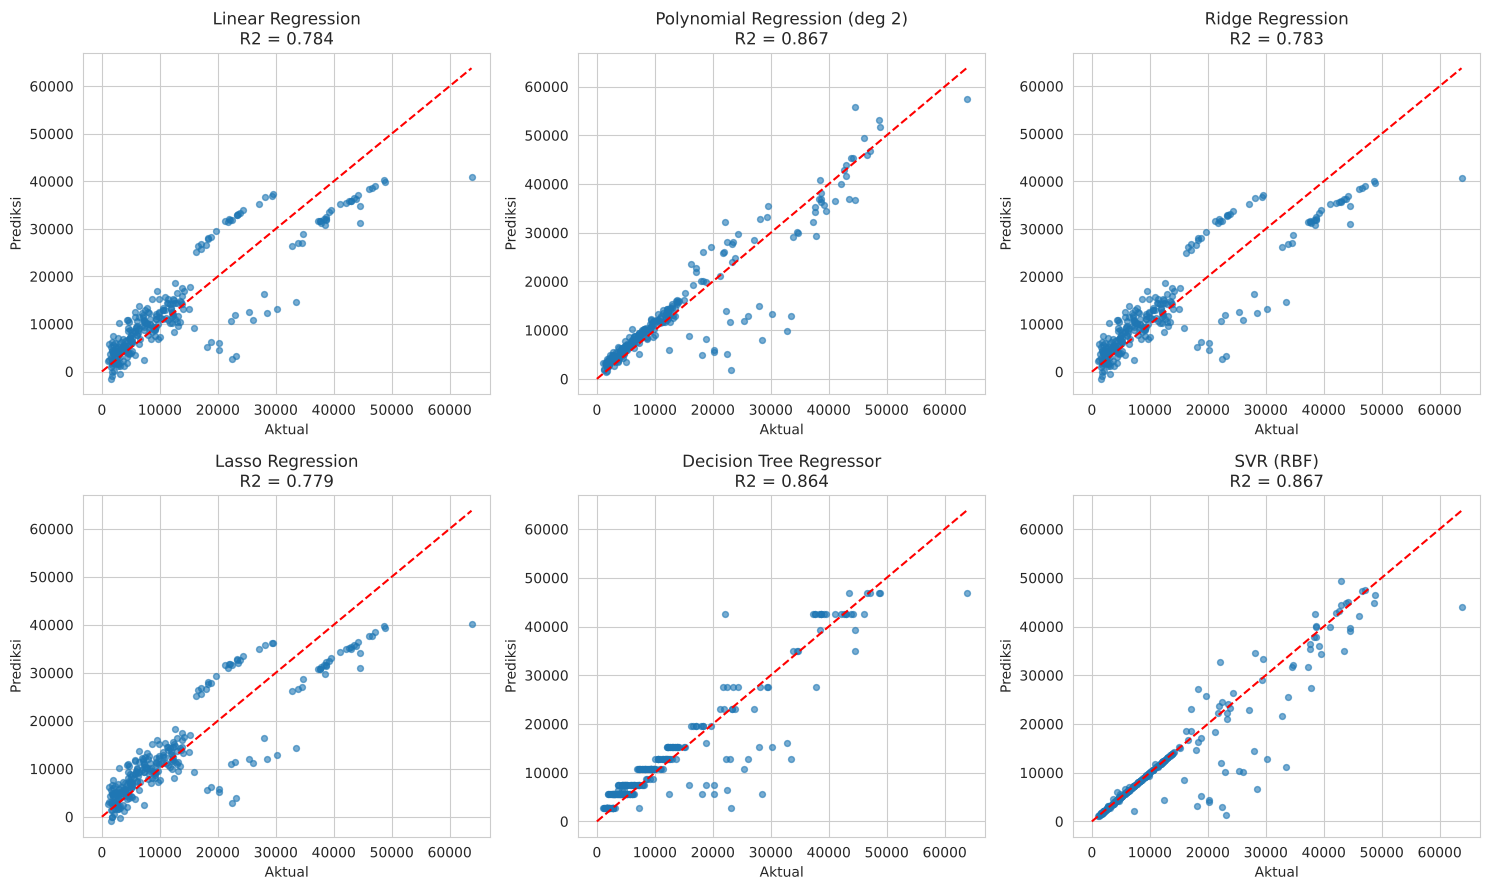

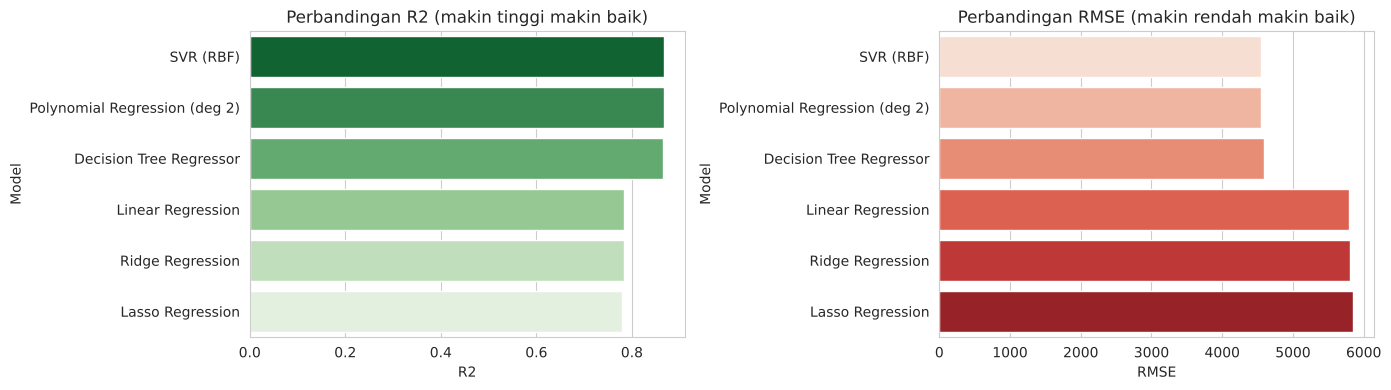

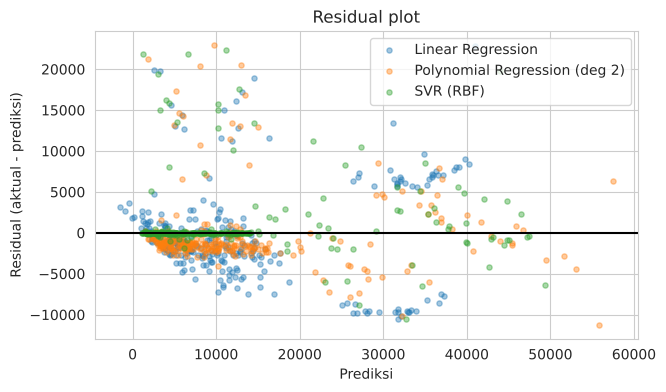

In [29]:
# Buat visualisasi perbandingan nilai aktual dan prediksi jika diperlukan.
# Aktual vs prediksi
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ax.scatter(y_test, pred, alpha=0.6, s=18)
    lim = [0, max(y_test.max(), pred.max())]
    ax.plot(lim, lim, "r--", label="Prediksi ideal")
    ax.set_title(f"{name}\nR2 = {r2_score(y_test, pred):.3f}")
    ax.set_xlabel("Aktual")
    ax.set_ylabel("Prediksi")
plt.tight_layout()
plt.show()

# Perbandingan metrik
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=results, y="Model", x="R2", ax=ax[0], palette="Greens_r")
ax[0].set_title("Perbandingan R2 (makin tinggi makin baik)")
sns.barplot(data=results, y="Model", x="RMSE", ax=ax[1], palette="Reds")
ax[1].set_title("Perbandingan RMSE (makin rendah makin baik)")
plt.tight_layout()
plt.show()

# Plot residual
plt.figure(figsize=(7, 4))
for name in ["Linear Regression", "Polynomial Regression (deg 2)", "SVR (RBF)"]:
    plt.scatter(predictions[name], y_test - predictions[name], alpha=0.4, s=14, label=name)
plt.axhline(0, color="black")
plt.xlabel("Prediksi")
plt.ylabel("Residual (aktual - prediksi)")
plt.title("Residual plot")
plt.legend()
plt.show()

# 5. Analisis

#### Bandingkan hasil Linear Regression, Polynomial Regression, Ridge, Lasso, Decision Tree Regressor, dan SVR berdasarkan metrik evaluasi. Jelaskan pengaruh preprocessing dan parameter yang digunakan terhadap hasil.

### 5.1 Perbandingan hasil

| Model | MAE | RMSE | R² |
|---|---|---|---|
| SVR (RBF, C=100000) | 1.718,56 | 4.547,59 | 0,8668 |
| Polynomial Regression (degree 2) | 2.729,50 | 4.551,13 | 0,8666 |
| Decision Tree (max_depth=4) | 2.697,77 | 4.592,76 | 0,8641 |
| Linear Regression | 4.181,19 | 5.796,28 | 0,7836 |
| Ridge (alpha=1) | 4.193,20 | 5.800,46 | 0,7833 |
| Lasso (alpha=100) | 4.248,49 | 5.853,72 | 0,7793 |

Hasilnya terbagi menjadi dua kelompok. **SVR, Polynomial Regression, dan Decision Tree** punya R² sekitar 0,86-0,87. **Linear, Ridge, dan Lasso** hanya sekitar 0,78. Selisih di dalam masing-masing kelompok sangat kecil, sedangkan selisih antar kelompok jelas.

### 5.2 Mengapa model non-linear lebih baik?

Dari EDA, hubungan `charges` dengan fitur tidak murni linear. Pengaruh `bmi` baru besar jika orangnya perokok. Linear Regression hanya bisa menjumlahkan pengaruh tiap fitur, sehingga tidak menangkap interaksi ini. Polynomial degree 2 menambahkan suku perkalian antar fitur (misalnya `smoker x bmi`), dan Decision Tree membuat percabangan (perokok atau bukan, lalu BMI di atas atau di bawah batas tertentu). SVR dengan kernel RBF juga bisa membentuk batas yang melengkung. Itu sebabnya ketiganya naik sekitar 0,08 pada R².

### 5.3 Pengaruh preprocessing

- **OneHotEncoder** diperlukan karena `sex`, `smoker`, dan `region` berupa teks. Pada model linear digunakan `drop="first"` agar tidak terjadi dummy variable trap.
- **StandardScaler** penting untuk SVR. Tanpa scaling, `age`, `bmi`, dan `children` berada pada skala berbeda sehingga jarak pada kernel RBF didominasi fitur berskala besar. Pada Ridge dan Lasso, scaling juga penting karena penalti diberikan pada ukuran koefisien.
- Decision Tree tidak memakai scaling karena pemisahan node hanya bergantung pada urutan nilai, bukan skalanya.
- Scaler dan encoder hanya di-`fit` pada data train, sehingga data test tidak bocor ke proses training.

### 5.4 Pengaruh parameter

- **Polynomial:** degree 1 sama dengan Linear Regression. Degree 2 menaikkan CV R² dari 0,733 ke 0,827. Degree 3 dan 4 turun (0,814 dan 0,713) karena jumlah fitur melonjak (8 menjadi 164 dan 494) sehingga model mulai overfitting.
- **Ridge dan Lasso:** hasilnya hampir sama dengan Linear Regression. Datanya relatif sedikit fitur (hanya 8) dan tidak terlalu multikolinear, jadi regularisasi hampir tidak membantu. Alpha yang terlalu besar justru menurunkan performa (underfitting). Pada Lasso, koefisien `sex` dan sebagian `region` menjadi 0, artinya fitur-fitur yang memang lemah itu otomatis disingkirkan. Hal ini sejalan dengan hasil EDA.
- **Decision Tree:** kedalaman 4 terbaik. Pohon yang terlalu dalam dengan `min_samples_leaf=1` mulai menghafal data train (CV R² turun menjadi 0,71 pada depth 10). Menaikkan `min_samples_leaf` membuat pohon yang dalam lebih stabil. Fitur terpenting menurut pohon adalah `smoker`, lalu `bmi` dan `age`.
- **SVR:** parameter default (C=1) sangat buruk (R² negatif, hampir sama dengan memprediksi rata-rata) karena `charges` bernilai puluhan ribu sedangkan epsilon dan C default terlalu kecil. Setelah C dinaikkan menjadi 100000 dengan kernel RBF, R² naik menjadi 0,867. Kernel linear tetap lebih rendah (CV R² sekitar 0,65).

### 5.5 Catatan tentang MAE

SVR punya R² yang sama dengan Polynomial, tetapi MAE-nya jauh lebih kecil (sekitar 1.719 dibanding 2.730). Artinya SVR lebih akurat pada kebanyakan data biasa, tetapi masih punya beberapa kesalahan besar pada data ekstrem sehingga RMSE-nya tidak jauh berbeda. Hal ini wajar karena SVR bekerja dengan loss yang tidak terlalu terpengaruh kesalahan kecil (epsilon-insensitive), dan RMSE sangat sensitif terhadap outlier.

# 6. Kesimpulan dan Saran

#### Berikan kesimpulan berdasarkan hasil eksperimen. Saran dapat berupa perubahan parameter, preprocessing, atau eksperimen lanjutan.

### Kesimpulan

1. Dari enam model, **SVR (RBF)**, **Polynomial Regression degree 2**, dan **Decision Tree** adalah yang terbaik dengan R² sekitar 0,86-0,87. SVR sedikit unggul (R² 0,8668 dan MAE terkecil), tetapi selisihnya dengan Polynomial sangat tipis sehingga dengan satu kali pembagian data belum bisa dikatakan jauh lebih baik.
2. Linear Regression, Ridge, dan Lasso hanya mencapai R² sekitar 0,78 karena tidak bisa menangkap interaksi antara `smoker`, `bmi`, dan `age`.
3. Regularisasi (Ridge dan Lasso) tidak memperbaiki hasil secara berarti pada dataset ini, tetapi Lasso berguna untuk menunjukkan fitur yang tidak penting (`sex` dan sebagian `region`).
4. Faktor yang paling menentukan biaya medis adalah status perokok, kemudian BMI dan usia.
5. Pemilihan parameter sangat berpengaruh, terutama pada SVR (C) dan Decision Tree (`max_depth`). Scaling wajib untuk SVR, sedangkan Decision Tree tidak membutuhkannya.

### Saran

- Gunakan **GridSearchCV** yang lebih lengkap, misalnya untuk `gamma` dan `epsilon` pada SVR, atau `min_samples_split` pada Decision Tree.
- Tambahkan fitur baru, seperti kategori obesitas (`bmi >= 30`) dan interaksi `smoker x bmi`. Dengan fitur ini model linear kemungkinan bisa mendekati hasil model non-linear.
- Coba transformasi `log(charges)` karena target miring ke kanan, supaya kesalahan pada biaya besar tidak terlalu mendominasi.
- Coba model ensemble seperti Random Forest atau Gradient Boosting, serta gunakan cross validation pada tahap evaluasi akhir agar hasil tidak bergantung pada satu pembagian train-test.